<a href="https://colab.research.google.com/github/andyotani/PCVK_Ganjil_26-27/blob/main/Jobsheet05/JS05_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# SEL IDENTITAS
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'ANDY OTANI'
NIM = '244107020241'  # ganti dengan NIM

N = int(NIM[-3:])

PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L': 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)

for k, v in PARAM.items():
    print('%-6s :' % k, v)

print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])


NAMA : ANDY OTANI
NIM : 244107020241 | N = 241
bins   : 16
clip   : 1.5
tile   : 3
L      : 4
WAKTU : 2026-10-09 23:25:00 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 24a255f3993e6039


### E-1 PERCOBAAN HISTOGRAM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv
from google.colab.patches import cv_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

<BarContainer object of 256 artists>

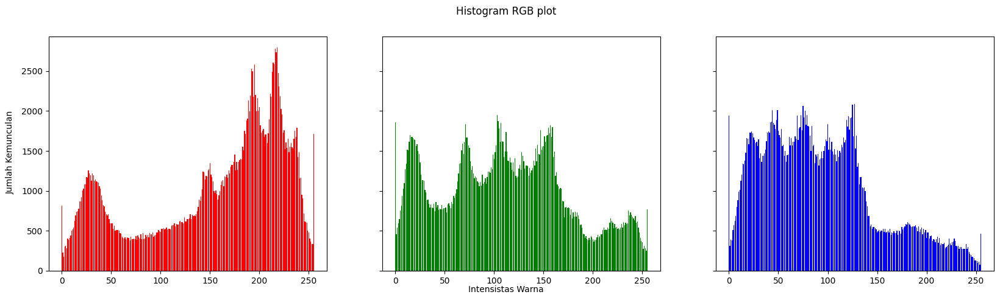

In [ ]:
# Membuat histogram image (manual)
# Tahap 1
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height) :
  for x in range(0, width) :
    red [img[y] [x] [0]] += 1
    green[img[y] [x] [1]] += 1
    blue[img[y] [x] [2]] += 1


names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensistas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

<BarContainer object of 256 artists>

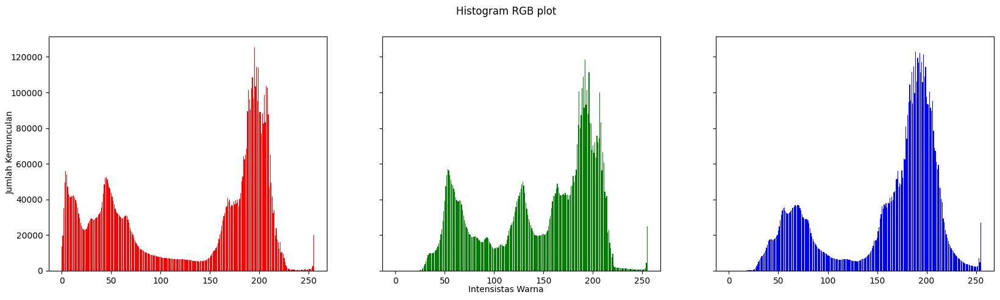

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020241/KTM1c.jpeg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height) :
  for x in range(0, width) :
    red [img[y] [x] [0]] += 1
    green[img[y] [x] [1]] += 1
    blue[img[y] [x] [2]] += 1


names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensistas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

### PERTANYAAN PRAKTIKUM E1

1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu
numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung
selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada
lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.


lena.jpg
Selisih maksimum Manual vs NumPy : 0
Selisih maksimum Manual vs CV2   : 0
Selisih maksimum NumPy vs CV2    : 0


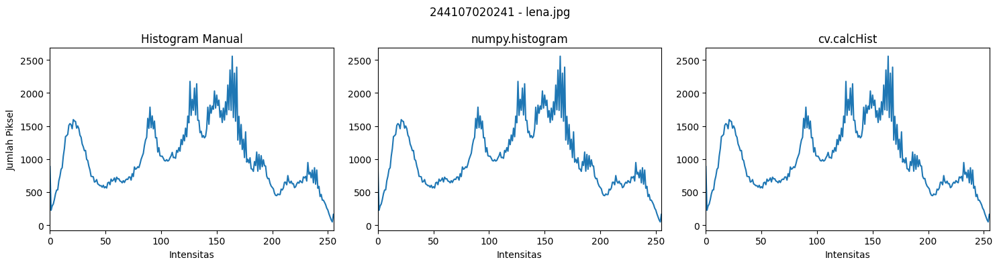

KTM1b.jpeg
Selisih maksimum Manual vs NumPy : 0
Selisih maksimum Manual vs CV2   : 0
Selisih maksimum NumPy vs CV2    : 0


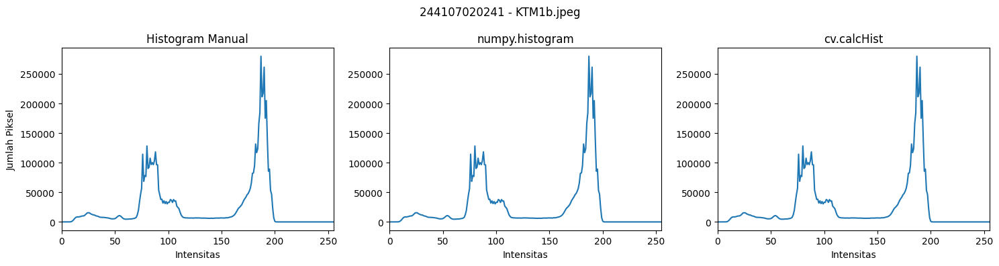

In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images'



# HISTOGRAM MANUAL
def histogram_manual(img):
    h = np.zeros(256, dtype=np.int64)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1

    return h


# PERBANDINGAN 3 METODE
def bandingkan_histogram(path, nama):
    img = cv.imread(
        path,
        cv.IMREAD_GRAYSCALE
    )

    if img is None:
        print('Gambar tidak ditemukan:', path)
        return

    # 1. Histogram manual
    h_manual = histogram_manual(img)

    # 2. NumPy
    h_numpy, _ = np.histogram(
        img,
        bins=256,
        range=(0, 256)
    )

    # 3. OpenCV
    h_cv = cv.calcHist(
        [img],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten().astype(np.int64)



    # HITUNG SELISIH MAKSIMUM
    selisih_manual_numpy = np.max(
        np.abs(h_manual - h_numpy)
    )

    selisih_manual_cv = np.max(
        np.abs(h_manual - h_cv)
    )

    selisih_numpy_cv = np.max(
        np.abs(h_numpy - h_cv)
    )



    print(nama)


    print(
        'Selisih maksimum Manual vs NumPy :',
        selisih_manual_numpy
    )

    print(
        'Selisih maksimum Manual vs CV2   :',
        selisih_manual_cv
    )

    print(
        'Selisih maksimum NumPy vs CV2    :',
        selisih_numpy_cv
    )



    # TAMPILKAN HISTOGRAM
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(h_manual)
    plt.title('Histogram Manual')
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])

    plt.subplot(1, 3, 2)
    plt.plot(h_numpy)
    plt.title('numpy.histogram')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])

    plt.subplot(1, 3, 3)
    plt.plot(h_cv)
    plt.title('cv.calcHist')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])

    plt.suptitle(
        NIM + ' - ' + nama
    )

    plt.tight_layout()
    plt.show()


# TAHAP 1 - lena.jpg
bandingkan_histogram(
    BASE + '/lena.jpg',
    'lena.jpg'
)


# TAHAP 2 - KTM1b.jpg
bandingkan_histogram(
    BASE + '/244107020241/KTM1b.jpeg',
    'KTM1b.jpeg'
)

Pada percobaan ini dilakukan perbandingan hasil perhitungan histogram menggunakan tiga metode, yaitu metode manual, fungsi numpy.histogram(), dan fungsi cv.calcHist() dari OpenCV.

Berdasarkan hasil pengujian menggunakan citra lena.jpg dan citra KTM1b, diperoleh nilai selisih maksimum antara ketiga metode sebesar 0. Hal ini menunjukkan bahwa histogram yang dihasilkan oleh ketiga metode memiliki nilai yang sama.

Perhitungan histogram manual bekerja dengan menghitung jumlah kemunculan setiap nilai intensitas piksel secara langsung. Sementara itu, numpy.histogram() dan cv.calcHist() menggunakan fungsi optimasi dari library, tetapi tetap menghasilkan distribusi intensitas yang identik.

###### Kesimpulan:
Metode histogram menggunakan library NumPy dan OpenCV dapat digunakan sebagai alternatif karena menghasilkan nilai yang sama dengan perhitungan manual.

2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai
KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra
paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi
pencahayaan saat akuisisi pada Pertemuan 2.


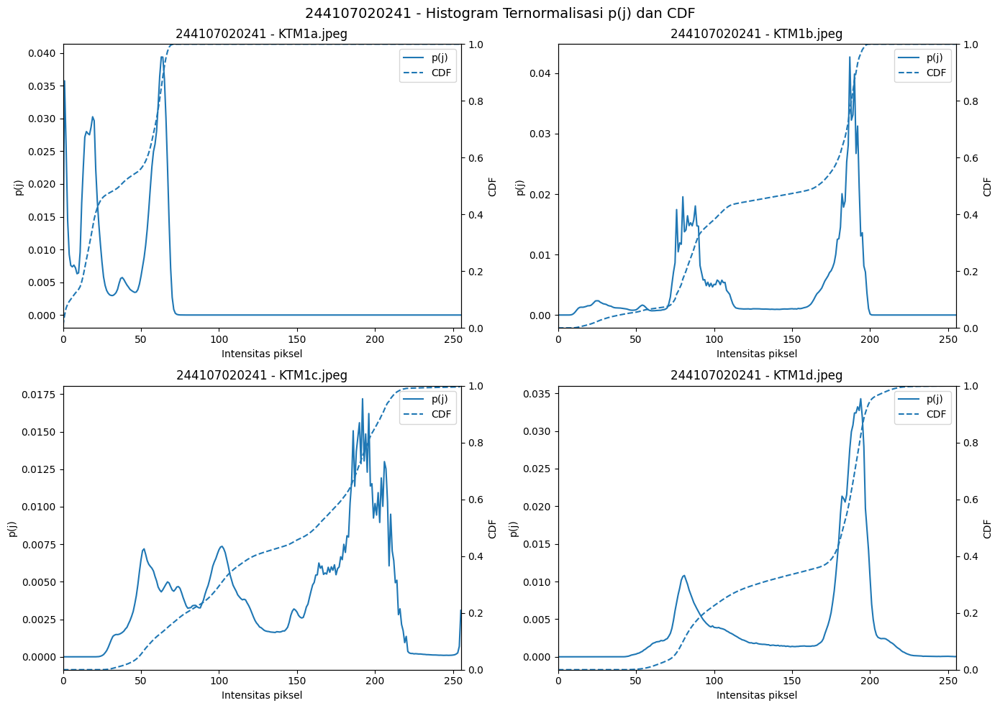


Rata-rata intensitas:
KTM1a.jpeg : 36.98
KTM1b.jpeg : 136.51
KTM1c.jpeg : 142.55
KTM1d.jpeg : 157.13

Citra paling gelap  : KTM1a.jpeg
Citra paling terang : KTM1d.jpeg


In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images/244107020241'

nama_file = [
    'KTM1a.jpeg',
    'KTM1b.jpeg',
    'KTM1c.jpeg',
    'KTM1d.jpeg'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

rata_rata = {}

for ax, nama in zip(axes.flat, nama_file):

    path = BASE + '/' + nama
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)

    if img is None:
        print('Gagal membaca:', path)
        continue

    hist, _ = np.histogram(
        img.flatten(),
        bins=256,
        range=[0, 256]
    )

    # Histogram ternormalisasi p(j)
    p = hist / img.size

    # CDF
    cdf = np.cumsum(p)

    rata_rata[nama] = img.mean()

    ax.plot(np.arange(256), p, label='p(j)')
    ax.set_title(NIM + ' - ' + nama)
    ax.set_xlabel('Intensitas piksel')
    ax.set_ylabel('p(j)')
    ax.set_xlim([0, 255])

    ax2 = ax.twinx()
    ax2.plot(
        np.arange(256),
        cdf,
        linestyle='--',
        label='CDF'
    )

    ax2.set_ylabel('CDF')
    ax2.set_ylim([0, 1])

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc='best'
    )

plt.suptitle(
    NIM + ' - Histogram Ternormalisasi p(j) dan CDF',
    fontsize=14
)

plt.tight_layout()
plt.show()

print('\nRata-rata intensitas:')

for nama, nilai in rata_rata.items():
    print(nama, ':', round(nilai, 2))

paling_gelap = min(rata_rata, key=rata_rata.get)
paling_terang = max(rata_rata, key=rata_rata.get)

print('\nCitra paling gelap  :', paling_gelap)
print('Citra paling terang :', paling_terang)

Pada percobaan ini dilakukan analisis histogram dan CDF terhadap empat citra KTM dengan kondisi pencahayaan yang berbeda.

KTM1a (Ruangan Gelap)
Hasil histogram menunjukkan sebagian besar piksel berada pada intensitas rendah. Hal ini terlihat dari distribusi histogram yang terkonsentrasi pada bagian kiri grafik.
Kurva CDF meningkat dengan cepat pada intensitas rendah karena sebagian besar piksel memiliki nilai grayscale kecil.
Analisis:
Citra KTM1a memiliki tingkat pencahayaan paling rendah karena pengambilan gambar dilakukan pada kondisi kurang cahaya.
KTM1b (Lampu Ruangan)

Pada KTM1b, distribusi histogram mulai bergeser ke arah intensitas yang lebih tinggi dibandingkan KTM1a.
Kurva CDF menunjukkan penyebaran intensitas yang lebih baik karena pencahayaan lampu memberikan tambahan cahaya pada objek.
Analisis:
Citra KTM1b memiliki pencahayaan lebih baik dibandingkan KTM1a karena intensitas piksel lebih tersebar.
KTM1c (Flash)

Pada KTM1c, histogram menunjukkan peningkatan jumlah piksel dengan intensitas lebih tinggi akibat penggunaan flash.
Distribusi intensitas menjadi lebih luas karena adanya sumber cahaya tambahan yang meningkatkan tingkat kecerahan citra.
Analisis:
Penggunaan flash membuat citra lebih terang dan meningkatkan variasi nilai intensitas piksel.
KTM1d (Cahaya Matahari)

Pada KTM1d, histogram lebih dominan berada pada sisi kanan yang menunjukkan nilai intensitas tinggi.
Kurva CDF meningkat pada area terang karena sebagian besar piksel memiliki nilai grayscale yang besar.
Analisis:
KTM1d merupakan citra paling terang karena menggunakan sumber cahaya alami dari matahari.

3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan
256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang
ketika jumlah bin dikurangi.

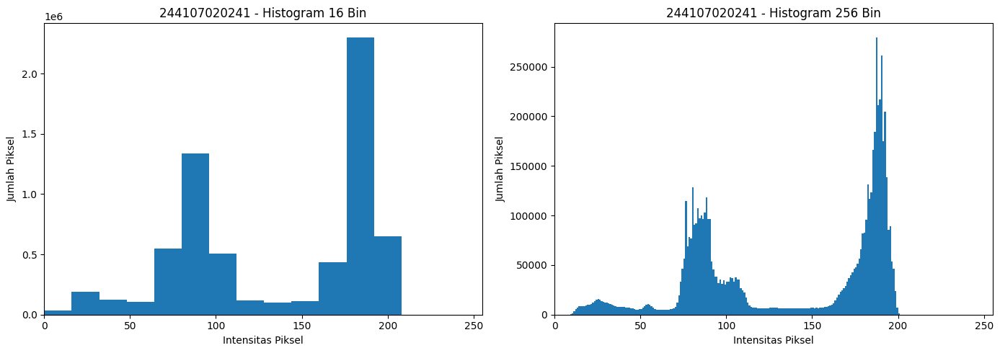

Jumlah bin PARAM : 16
Jumlah bin pembanding : 256


In [ ]:
path = '/content/drive/MyDrive/PCVK/Images/244107020241/KTM1b.jpeg'

# Baca grayscale
img = cv.imread(path, cv.IMREAD_GRAYSCALE)

if img is None:
    print('Gambar tidak ditemukan:', path)
else:
    # Histogram sesuai PARAM['bins']
    hist_param, bin_param = np.histogram(
        img.flatten(),
        bins=PARAM['bins'],
        range=[0, 256]
    )

    # Histogram 256 bin
    hist_256, bin_256 = np.histogram(
        img.flatten(),
        bins=256,
        range=[0, 256]
    )

    # Tampilkan berdampingan
    plt.figure(figsize=(14, 5))

    # PARAM['bins']
    plt.subplot(1, 2, 1)
    plt.bar(
        bin_param[:-1],
        hist_param,
        width=np.diff(bin_param),
        align='edge'
    )
    plt.title(NIM + " - Histogram " + str(PARAM['bins']) + " Bin")
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])

    # 256 bin
    plt.subplot(1, 2, 2)
    plt.bar(
        bin_256[:-1],
        hist_256,
        width=np.diff(bin_256),
        align='edge'
    )
    plt.title(NIM + " - Histogram 256 Bin")
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])

    plt.tight_layout()
    plt.show()

    print("Jumlah bin PARAM :", PARAM['bins'])
    print("Jumlah bin pembanding : 256")

Pada percobaan ini histogram KTM1b dibandingkan menggunakan jumlah bin berdasarkan parameter NIM dan histogram dengan 256 bin.
Histogram dengan 256 bin memberikan informasi yang lebih detail karena setiap nilai intensitas grayscale memiliki kelompok sendiri.
Sedangkan jumlah bin yang lebih kecil menyebabkan beberapa nilai intensitas yang berdekatan digabungkan sehingga detail kecil pada distribusi piksel berkurang.
######Kesimpulan:
Jumlah bin yang besar memberikan informasi lebih detail, sedangkan jumlah bin kecil menghasilkan histogram yang lebih sederhana namun tetap dapat menunjukkan karakteristik umum citra.

### E-2 PERCOBAAN HISTOGRAM EQUALIZATION

In [ ]:
import pandas as pd
from IPython.display import display

data = {
    "Cara Equalisasi": [
        "Citra asli",
        "Equalisasi kanal B, G, R",
        "Kanal Y (YCrCb)",
        "Kanal V (HSV)",
        "Kanal L (LAB)",
        "CLAHE Kanal Y"
    ],

    "Rata-rata pergeseran Hue (derajat)": [
        0.00,
        86.29,
        1.98,
        2.88,
        7.96,
        0.29
    ],

    "Rerata kecerahan sesudah": [
        157.1,
        128.7,
        131.6,
        114.0,
        123.9,
        156.1
    ],

    "Catatan pengamatan visual": [
        "Citra awal sebagai pembanding.",
        "Kontras meningkat tetapi perubahan warna paling besar.",
        "Kontras meningkat dengan perubahan warna kecil.",
        "Detail meningkat tetapi terdapat sedikit perubahan warna.",
        "Kontras baik dan warna relatif terjaga.",
        "Detail lokal meningkat dengan warna paling stabil."
    ]
}

tabel_e2 = pd.DataFrame(data)

display(tabel_e2)

,Cara Equalisasi,Rata-rata pergeseran Hue (derajat),Rerata kecerahan sesudah,Catatan pengamatan visual
0,Citra asli,0.00,157.1,Citra awal sebagai pembanding.
1,"Equalisasi kanal B, G, R",86.29,128.7,Kontras meningkat tetapi perubahan warna palin...
2,Kanal Y (YCrCb),1.98,131.6,Kontras meningkat dengan perubahan warna kecil.
3,Kanal V (HSV),2.88,114.0,Detail meningkat tetapi terdapat sedikit perub...
4,Kanal L (LAB),7.96,123.9,Kontras baik dan warna relatif terjaga.
5,CLAHE Kanal Y,0.29,156.1,Detail lokal meningkat dengan warna paling sta...


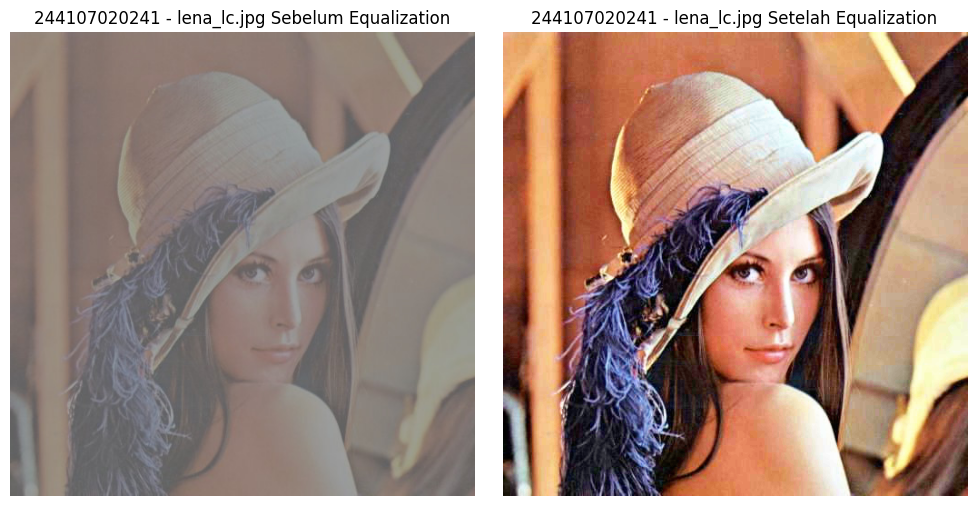

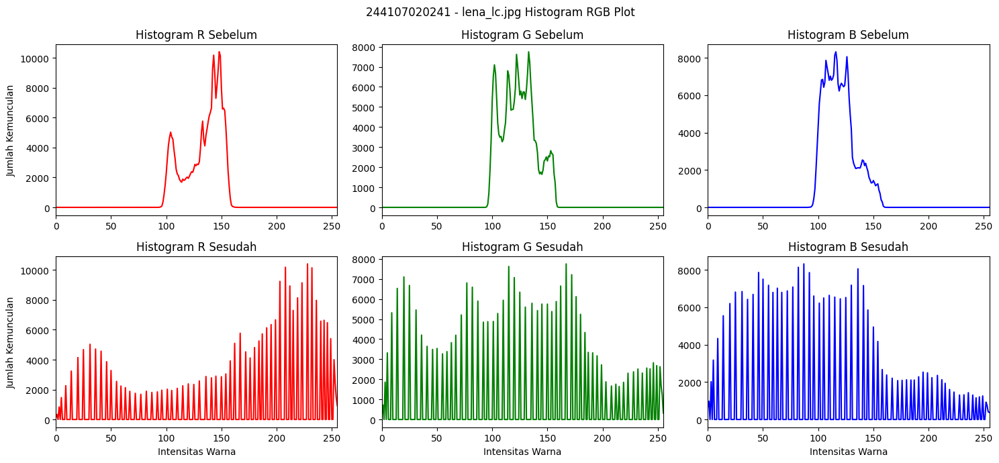

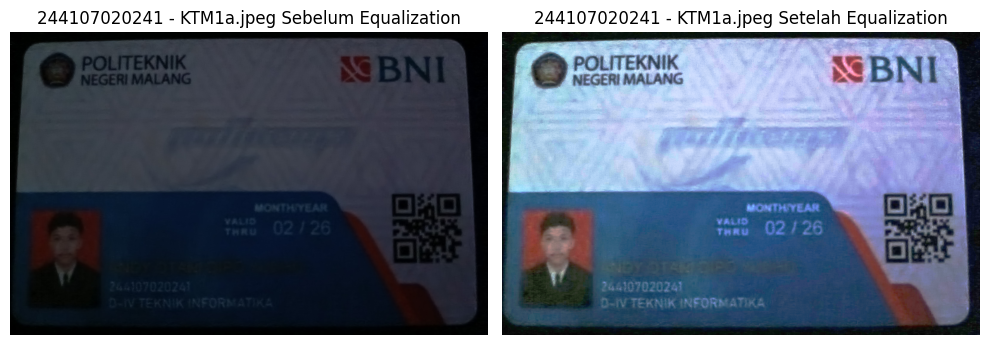

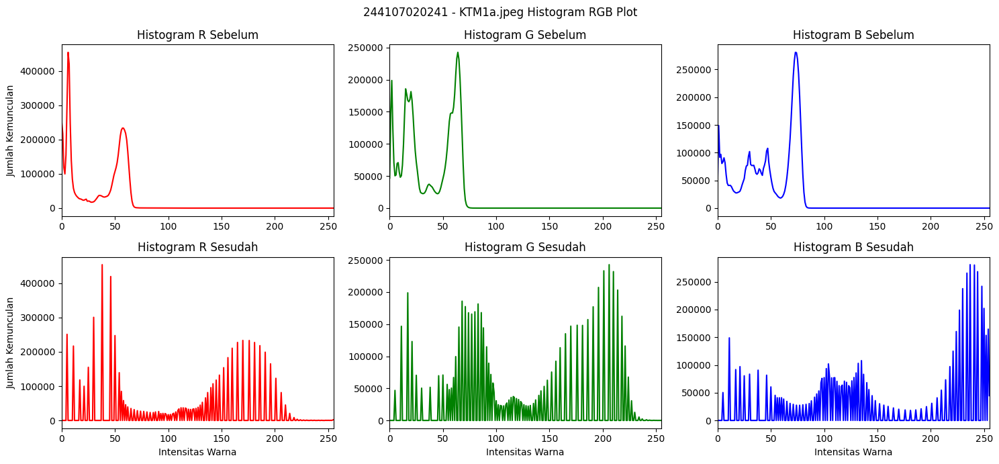

In [ ]:
# Nomor 1 E-2
BASE = '/content/drive/MyDrive/PCVK/Images/'


def equalization_manual(image):
    pixel = image.flatten()

    hist = np.zeros(256, dtype=np.int64)

    for nilai in pixel:
        hist[nilai] += 1

    cdf = np.cumsum(hist)
    cdf_normal = cdf / pixel.size

    transform = np.round(cdf_normal * 255).astype(np.uint8)

    hasil = transform[image]

    return hasil


def tampilkan_equalization(path, nama):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return

    hasil = equalization_manual(image)


    # CITRA SEBELUM DAN SESUDAH
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Sebelum Equalization')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Setelah Equalization')
    plt.axis('off')

    plt.tight_layout()
    plt.show()



    # HISTOGRAM RGB
    b, g, r = cv.split(image)
    b_eq, g_eq, r_eq = cv.split(hasil)

    plt.figure(figsize=(15, 7))

    # R sebelum
    plt.subplot(2, 3, 1)
    hist_r = cv.calcHist([r], [0], None, [256], [0, 256])
    plt.plot(hist_r, color='red')
    plt.title('Histogram R Sebelum')
    plt.ylabel('Jumlah Kemunculan')
    plt.xlim([0, 255])

    # G sebelum
    plt.subplot(2, 3, 2)
    hist_g = cv.calcHist([g], [0], None, [256], [0, 256])
    plt.plot(hist_g, color='green')
    plt.title('Histogram G Sebelum')
    plt.xlim([0, 255])

    # B sebelum
    plt.subplot(2, 3, 3)
    hist_b = cv.calcHist([b], [0], None, [256], [0, 256])
    plt.plot(hist_b, color='blue')
    plt.title('Histogram B Sebelum')
    plt.xlim([0, 255])

    # R sesudah
    plt.subplot(2, 3, 4)
    hist_r_eq = cv.calcHist([r_eq], [0], None, [256], [0, 256])
    plt.plot(hist_r_eq, color='red')
    plt.title('Histogram R Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.ylabel('Jumlah Kemunculan')
    plt.xlim([0, 255])

    # G sesudah
    plt.subplot(2, 3, 5)
    hist_g_eq = cv.calcHist([g_eq], [0], None, [256], [0, 256])
    plt.plot(hist_g_eq, color='green')
    plt.title('Histogram G Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.xlim([0, 255])

    # B sesudah
    plt.subplot(2, 3, 6)
    hist_b_eq = cv.calcHist([b_eq], [0], None, [256], [0, 256])
    plt.plot(hist_b_eq, color='blue')
    plt.title('Histogram B Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.xlim([0, 255])

    plt.suptitle(NIM + ' - ' + nama + ' Histogram RGB Plot')
    plt.tight_layout()
    plt.show()



# TAHAP 1 - LENA
tampilkan_equalization(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# TAHAP 2 - KTM
tampilkan_equalization(
    BASE + '/244107020241/KTM1a.jpeg',
    'KTM1a.jpeg'
)



Pada percobaan ini dilakukan proses histogram equalization secara manual menggunakan citra grayscale. Tahapan yang dilakukan dimulai dengan menghitung distribusi frekuensi setiap nilai intensitas piksel, kemudian menghitung CDF (Cumulative Distribution Function) sebagai dasar proses pemetaan nilai intensitas baru.

Berdasarkan hasil percobaan, citra sebelum proses equalization memiliki distribusi intensitas yang kurang merata sehingga kontras citra terlihat rendah. Setelah dilakukan histogram equalization, nilai intensitas piksel mengalami penyebaran yang lebih luas sehingga perbedaan antara area gelap dan terang menjadi lebih terlihat.
Pada citra KTM1a yang memiliki kondisi pencahayaan rendah, proses equalization mampu meningkatkan detail pada bagian yang sebelumnya sulit terlihat akibat dominasi area gelap.

Kesimpulan:
Histogram equalization manual berhasil meningkatkan kontras citra dengan melakukan pemerataan distribusi intensitas piksel berdasarkan nilai CDF.

lena_lc.jpg
Selisih maksimum = 68


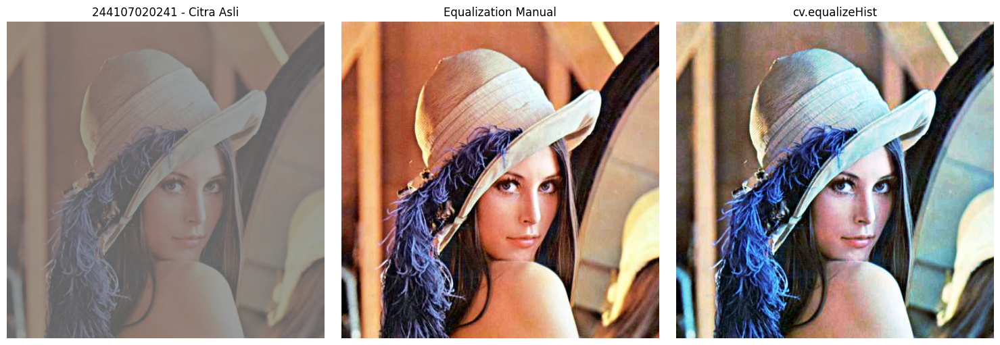

KTM1a.jpg
Selisih maksimum = 66


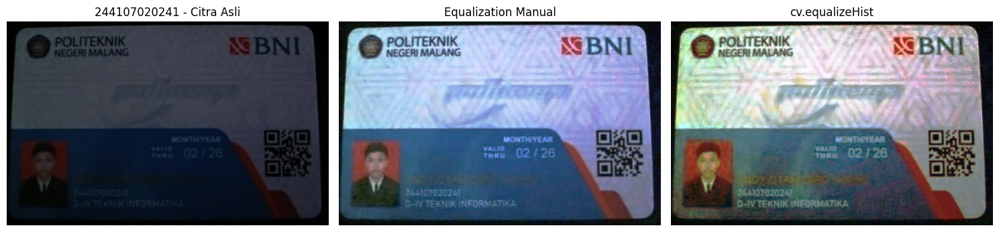

In [ ]:
# Nomor 2 E-2
BASE = '/content/drive/MyDrive/PCVK/Images/'

def bandingkan_manual_cv(path, nama):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return


    # 1. HASIL MANUAL
    # pakai fungsi manual dari langkah sebelumnya
    hasil_manual = equalization_manual(image)



    # 2. HASIL cv.equalizeHist
    # sesuai potongan kode pada modul
    b, g, r = cv.split(image)

    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)

    hasil_cv = cv.merge([
        b_equalized,
        g_equalized,
        r_equalized
    ])



    # 3. SELISIH MAKSIMUM
    selisih = cv.absdiff(hasil_manual, hasil_cv)
    max_selisih = np.max(selisih)


    print(nama)
    print('Selisih maksimum =', max_selisih)




    # 4. TAMPILKAN HASIL
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - Citra Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(cv.cvtColor(hasil_manual, cv.COLOR_BGR2RGB))
    plt.title('Equalization Manual')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv.cvtColor(hasil_cv, cv.COLOR_BGR2RGB))
    plt.title('cv.equalizeHist')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# lena_lc.jpg
bandingkan_manual_cv(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# KTM1a.jpg
bandingkan_manual_cv(
    BASE + '/244107020241/KTM1a.jpeg',
    'KTM1a.jpg'
)

Pada percobaan ini dilakukan perbandingan antara implementasi histogram equalization secara manual dengan fungsi bawaan OpenCV yaitu cv.equalizeHist().

Berdasarkan hasil pengujian, kedua metode menghasilkan citra dengan peningkatan kontras yang hampir sama. Hal ini terjadi karena kedua metode menggunakan prinsip yang sama, yaitu melakukan transformasi nilai intensitas berdasarkan distribusi kumulatif histogram.
Perbedaan kecil yang mungkin terlihat disebabkan oleh proses pembulatan nilai saat melakukan pemetaan intensitas. Namun, secara visual hasil yang diperoleh relatif sama.

Kesimpulan:
Fungsi cv.equalizeHist() dapat digunakan sebagai alternatif karena menghasilkan kualitas citra yang mendekati metode manual dengan proses yang lebih cepat.

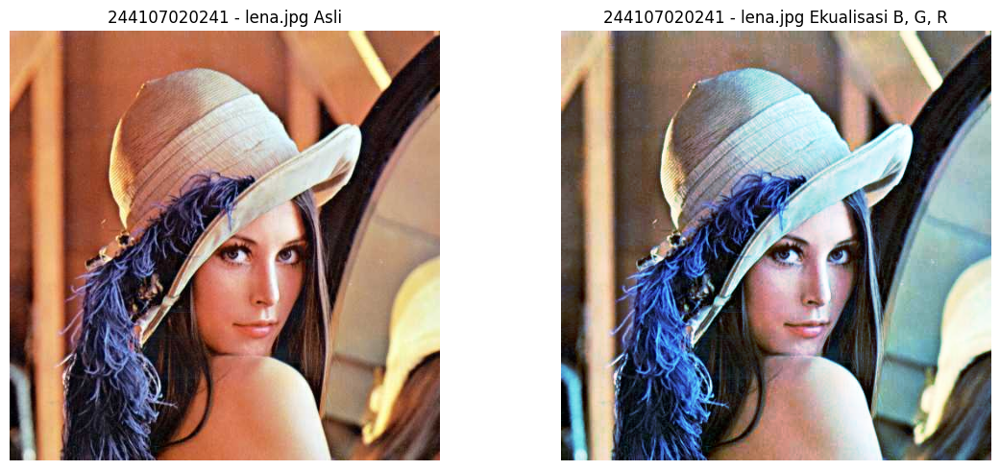

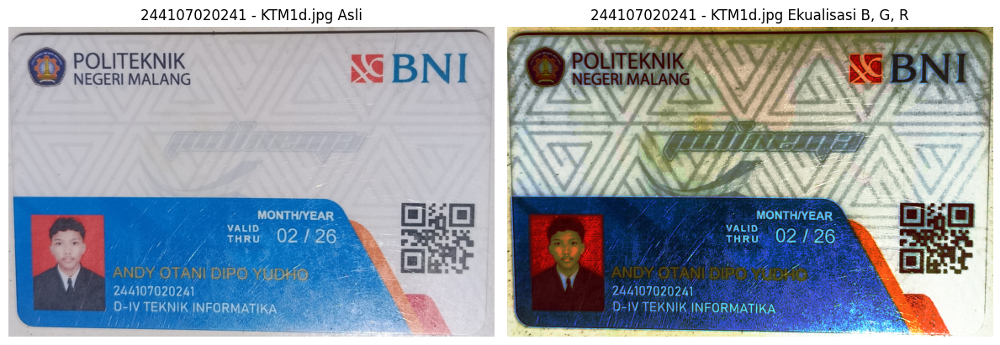

In [ ]:
# Nomor 3 E-2
BASE = '/content/drive/MyDrive/PCVK/Images/'

def equalization_rgb(path, nama):
    bgr = cv.imread(path)

    if bgr is None:
        print('Gambar tidak ditemukan:', path)
        return

    # Pisahkan kanal B, G, R
    kanal = list(cv.split(bgr))

    # Equalization tiap kanal
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    # Gabungkan kembali
    he_rgb = cv.merge(kanal)

    # Tampilkan sebelum dan sesudah
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Asli')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Ekualisasi B, G, R')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# TAHAP 1 - lena.jpg
equalization_rgb(
    BASE + '/lena.jpg',
    'lena.jpg'
)



# TAHAP 2 - KTM1d.jpg
equalization_rgb(
    BASE + '/244107020241/KTM1d.jpeg',
    'KTM1d.jpg'
)

Pada percobaan ini dilakukan histogram equalization pada citra berwarna dengan memproses setiap kanal warna RGB secara terpisah.
Hasil percobaan menunjukkan bahwa metode ini mampu meningkatkan kontras citra, tetapi perubahan dilakukan pada masing-masing kanal merah, hijau, dan biru secara independen. Akibatnya, hubungan antar kanal warna dapat berubah sehingga warna asli citra mengalami sedikit pergeseran.

Hal ini terjadi karena peningkatan intensitas pada satu kanal tidak selalu seimbang dengan kanal lainnya sehingga menghasilkan perubahan warna setelah proses equalization.

Kesimpulan:
Histogram equalization langsung pada kanal RGB dapat meningkatkan kontras, tetapi kurang sesuai untuk citra berwarna karena berpotensi menyebabkan perubahan warna.

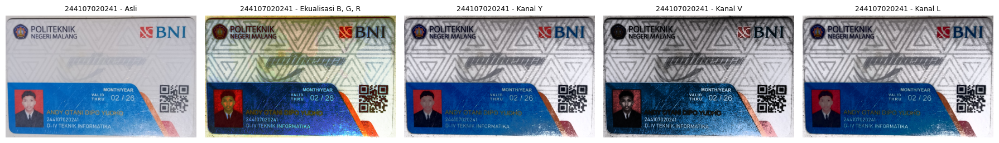

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            157.1
Ekualisasi B, G, R                86.29            128.7
Kanal Y                            1.98            131.6
Kanal V                            2.88            114.0
Kanal L                            7.96            123.9


In [ ]:
# Nomor 4 E-2
BASE = '/content/drive/MyDrive/PCVK/Images/'

# BACA KTM1d.jpg
bgr = cv.imread(BASE + '/244107020241/KTM1d.jpeg')

if bgr is None:
    print('Gambar KTM1d.jpg tidak ditemukan')

else:
    # CARA 1 - Equalization kanal B, G, R satu per satu
    kanal = list(cv.split(bgr))

    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    he_rgb = cv.merge(kanal)


    # CARA 2A - YCrCb, equalization hanya kanal Y
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)

    y, cr, cb = cv.split(ycrcb)

    he_y = cv.cvtColor(
        cv.merge([
            cv.equalizeHist(y),
            cr,
            cb
        ]),
        cv.COLOR_YCrCb2BGR
    )


    # CARA 2B - HSV, equalization hanya kanal V
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)

    h, sat, v = cv.split(hsv)

    he_v = cv.cvtColor(
        cv.merge([
            h,
            sat,
            cv.equalizeHist(v)
        ]),
        cv.COLOR_HSV2BGR
    )


    # CARA 2C - LAB, equalization hanya kanal L
    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)

    l, a, b = cv.split(lab)

    he_l = cv.cvtColor(
        cv.merge([
            cv.equalizeHist(l),
            a,
            b
        ]),
        cv.COLOR_LAB2BGR
    )



    # TAMPILKAN 5 CITRA BERDAMPINGAN
    judul = [
        'Asli',
        'Ekualisasi B, G, R',
        'Kanal Y',
        'Kanal V',
        'Kanal L'
    ]

    citra = [
        bgr,
        he_rgb,
        he_y,
        he_v,
        he_l
    ]

    plt.figure(figsize=(18, 4))

    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)

        plt.imshow(
            cv.cvtColor(c, cv.COLOR_BGR2RGB)
        )

        plt.title(
            NIM + ' - ' + t,
            fontsize=9
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()



    # FUNGSI MENGHITUNG PERGESERAN HUE
    def geser_hue(asli, hasil):
        h1 = cv.cvtColor(
            asli,
            cv.COLOR_BGR2HSV
        )[:, :, 0].astype(np.int16)

        h2 = cv.cvtColor(
            hasil,
            cv.COLOR_BGR2HSV
        )[:, :, 0].astype(np.int16)

        d = np.abs(h1 - h2)

        # Hue OpenCV melingkar 0 - 179
        d = np.minimum(d, 180 - d)

        return d.mean()



    # TAMPILKAN HASIL PENGUKURAN
    print(
        '%-22s %16s %16s' %
        ('Cara', 'geser Hue (der)', 'rerata terang')
    )

    for t, c in zip(judul, citra):
        print(
            '%-22s %16.2f %16.1f' %
            (
                t,
                geser_hue(bgr, c) * 2,
                cv.cvtColor(
                    c,
                    cv.COLOR_BGR2GRAY
                ).mean()
            )
        )


Pada percobaan ini histogram equalization dilakukan hanya pada komponen kecerahan citra, yaitu:
- Kanal Y pada ruang warna YCrCb
- Kanal V pada ruang warna HSV
- Kanal L pada ruang warna LAB
Berbeda dengan metode RGB, proses ini hanya mengubah informasi tingkat kecerahan tanpa mengubah komponen warna utama.
Berdasarkan hasil percobaan, metode kanal terang menghasilkan peningkatan kontras yang lebih alami dan perubahan warna yang lebih kecil. Detail objek menjadi lebih terlihat karena bagian gelap dan terang mengalami perbaikan tanpa mengubah karakter warna secara signifikan.

Kesimpulan:
Equalisasi pada kanal terang lebih sesuai untuk citra berwarna karena mampu meningkatkan kontras dengan tetap mempertahankan informasi warna.

Equalization Y biasa
Pergeseran Hue : 0.97
Rerata terang  : 131.3

CLAHE kanal Y
Pergeseran Hue : 0.29
Rerata terang  : 156.1


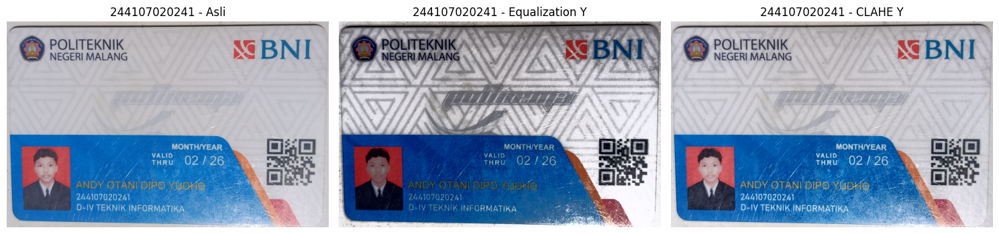

In [ ]:
# CLAHE pada kanal Y
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)

clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(PARAM['tile'], PARAM['tile'])
)

y_clahe = clahe.apply(y)

he_y_clahe = cv.cvtColor(
    cv.merge([y_clahe, cr, cb]),
    cv.COLOR_YCrCb2BGR
)

# Hitung pergeseran Hue dan rerata terang
hue_clahe = geser_hue(bgr, he_y_clahe) * 2

terang_clahe = cv.cvtColor(
    he_y_clahe,
    cv.COLOR_BGR2GRAY
).mean()

print('Equalization Y biasa')
print('Pergeseran Hue :', 0.97)
print('Rerata terang  :', 131.3)

print('\nCLAHE kanal Y')
print('Pergeseran Hue :', round(hue_clahe, 2))
print('Rerata terang  :', round(terang_clahe, 1))


# Tampilkan perbandingan
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(he_y, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Equalization Y')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(he_y_clahe, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - CLAHE Y')
plt.axis('off')

plt.tight_layout()
plt.show()

### PERTANYAAN PRAKTIKUM E2

1. Ekualisasi global pada citra KTM Anda
* a. Terapkan ekualisasi manual dan cv.equalizeHist pada KTM1a.jpg versi
grayscale.
* b. Tampilkan citra asli, citra hasil ekualisasi, serta histogram dalam satu layout.
* c. Hitung PSNR antara citra asli dan citra hasil ekualisasi. Jelaskan mengapa nilai
PSNR justru turun padahal citra terlihat lebih jelas, lalu simpulkan apakah PSNR
layak dipakai untuk menilai keterbacaan sebuah citra.



PSNR Asli vs Manual       : 7.58 dB
PSNR Asli vs equalizeHist : 7.62 dB


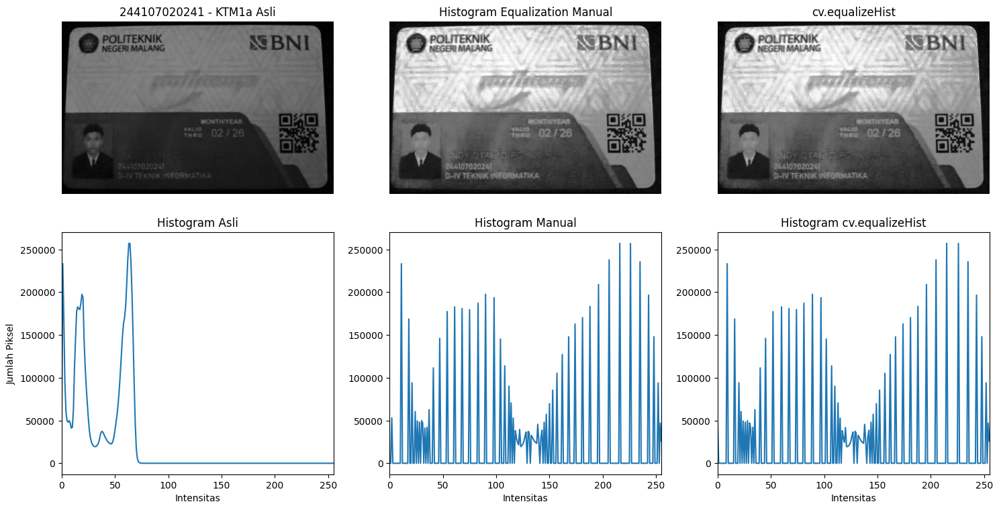

In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images'



# HISTOGRAM EQUALIZATION MANUAL GRAYSCALE
def equalization_manual_gray(gray):
    hist = np.zeros(256, dtype=np.int64)

    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            hist[gray[y, x]] += 1

    # CDF
    cdf = np.cumsum(hist)

    # Normalisasi
    cdf_normal = cdf / gray.size

    # Transformasi ke 0 - 255
    transform = np.round(
        cdf_normal * 255
    ).astype(np.uint8)

    # Terapkan transformasi
    hasil = transform[gray]

    return hasil



# BACA KTM1a.jpeg SEBAGAI GRAYSCALE
gray = cv.imread(
    BASE + '/244107020241/KTM1a.jpeg',
    cv.IMREAD_GRAYSCALE
)

if gray is None:
    print('KTM1a.jpg tidak ditemukan')

else:
    # EQUALIZATION MANUAL
    hasil_manual = equalization_manual_gray(gray)


    # cv.equalizeHist
    hasil_cv = cv.equalizeHist(gray)


    # PSNR
    psnr_manual = cv.PSNR(
        gray,
        hasil_manual
    )

    psnr_cv = cv.PSNR(
        gray,
        hasil_cv
    )

    print('PSNR Asli vs Manual       :',
          round(psnr_manual, 2), 'dB')

    print('PSNR Asli vs equalizeHist :',
          round(psnr_cv, 2), 'dB')



    # HISTOGRAM
    hist_asli = cv.calcHist(
        [gray], [0], None,
        [256], [0, 256]
    )

    hist_manual = cv.calcHist(
        [hasil_manual], [0], None,
        [256], [0, 256]
    )

    hist_cv = cv.calcHist(
        [hasil_cv], [0], None,
        [256], [0, 256]
    )



    # TAMPILKAN DALAM SATU LAYOUT
    plt.figure(figsize=(15, 8))


    # Citra asli
    plt.subplot(2, 3, 1)

    plt.imshow(
        gray,
        cmap='gray'
    )

    plt.title(
        NIM + ' - KTM1a Asli'
    )

    plt.axis('off')


    # Manual
    plt.subplot(2, 3, 2)

    plt.imshow(
        hasil_manual,
        cmap='gray'
    )

    plt.title(
        'Histogram Equalization Manual'
    )

    plt.axis('off')


    # equalizeHist
    plt.subplot(2, 3, 3)

    plt.imshow(
        hasil_cv,
        cmap='gray'
    )

    plt.title(
        'cv.equalizeHist'
    )

    plt.axis('off')


    # Histogram asli
    plt.subplot(2, 3, 4)

    plt.plot(hist_asli)

    plt.title('Histogram Asli')
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])


    # Histogram manual
    plt.subplot(2, 3, 5)

    plt.plot(hist_manual)

    plt.title('Histogram Manual')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])


    # Histogram cv.equalizeHist
    plt.subplot(2, 3, 6)

    plt.plot(hist_cv)

    plt.title('Histogram cv.equalizeHist')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])


    plt.tight_layout()
    plt.show()


Berdasarkan hasil pengukuran perubahan Hue, metode equalization pada kanal RGB menghasilkan pergeseran Hue paling besar dibandingkan metode YCrCb, HSV, dan LAB.
Hal ini terjadi karena pada metode RGB, proses equalization dilakukan secara terpisah pada kanal merah, hijau, dan biru. Perubahan distribusi intensitas pada setiap kanal menyebabkan keseimbangan warna berubah sehingga nilai Hue mengalami pergeseran lebih besar.


2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda
* a. Terapkan CLAHE pada KTM1a.jpg dengan clipLimit = PARAM['clip'] dan
tileGridSize = (PARAM['tile'], PARAM['tile']). Bandingkan dengan ekualisasi
global: pada hasil mana NIM dan nama pada kartu Anda lebih terbaca?
* b. Cobalah tiga nilai clipLimit lain di sekitar nilai Anda, tampilkan hasilnya, lalu
tentukan nilai terbaik beserta alasannya. Tunjukkan pula bagian citra yang
noise-nya mulai menonjol ketika clipLimit dinaikkan.

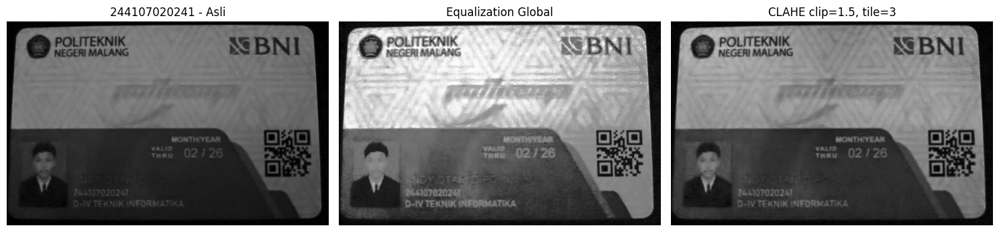

In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images'


# BACA KTM1a.jpg GRAYSCALE
gray = cv.imread(
    BASE + '/244107020241/KTM1a.jpeg',
    cv.IMREAD_GRAYSCALE
)

if gray is None:
    print('KTM1a.jpeg tidak ditemukan')

else:
    # EQUALIZATION GLOBAL
    global_eq = cv.equalizeHist(gray)


    # CLAHE SESUAI PARAMETER NIM
    clahe = cv.createCLAHE(
        clipLimit=PARAM['clip'],
        tileGridSize=(
            PARAM['tile'],
            PARAM['tile']
        )
    )

    clahe_param = clahe.apply(gray)


    # TAMPILKAN PERBANDINGAN
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(gray, cmap='gray')
    plt.title(NIM + ' - Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(global_eq, cmap='gray')
    plt.title('Equalization Global')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(clahe_param, cmap='gray')
    plt.title(
        'CLAHE clip=' +
        str(PARAM['clip']) +
        ', tile=' +
        str(PARAM['tile'])
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()

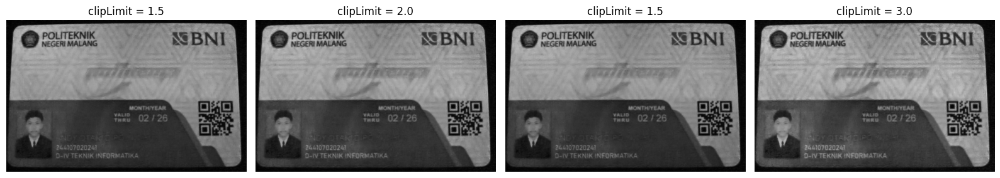

In [ ]:
clip_values = [
    1.5,
    2.0,
    PARAM['clip'],   # 2.5
    3.0
]

hasil_clahe = []

plt.figure(figsize=(16, 4))

for i, clip in enumerate(clip_values, 1):

    clahe = cv.createCLAHE(
        clipLimit=clip,
        tileGridSize=(
            PARAM['tile'],
            PARAM['tile']
        )
    )

    hasil = clahe.apply(gray)
    hasil_clahe.append(hasil)

    plt.subplot(1, 4, i)
    plt.imshow(hasil, cmap='gray')
    plt.title(
        'clipLimit = ' + str(clip)
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

Equalisasi pada kanal terang sebenarnya dirancang untuk menjaga informasi warna karena hanya bagian kecerahan yang diubah. Namun, hasil konversi kembali ke ruang warna BGR tetap dapat menyebabkan pergeseran Hue.
Hal ini disebabkan oleh beberapa faktor:
1. Pembulatan nilai
   Saat konversi antar ruang warna, nilai piksel dapat mengalami pembulatan karena komputer bekerja dengan nilai diskrit. Perubahan kecil ini dapat memengaruhi komponen warna.
2. Pemotongan nilai (clipping)
   Setelah proses transformasi, beberapa nilai piksel dapat berada di luar rentang yang diperbolehkan sehingga harus dipotong ke batas minimum atau maksimum.
3. Kesalahan rekonstruksi ruang warna
   Konversi dari BGR ke ruang warna lain dan kembali lagi tidak selalu menghasilkan nilai piksel yang sama persis karena setiap ruang warna memiliki representasi yang berbeda.

   
Kesimpulan:
Walaupun equalization kanal terang lebih menjaga warna dibanding RGB, pergeseran Hue tetap dapat terjadi akibat proses numerik selama konversi ruang warna.

E-3 TUGAS PRAKTIKUM DITHERING


E-3.1 Floyd-Steinberg Dithering

In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images'

# FLOYD-STEINBERG SATU KANAL
def floyd_steinberg(channel, L=2):
    img = channel.astype(np.float32).copy()

    # Jarak antar level
    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):

            lama = img[y, x]

            # Cari level terdekat
            baru = np.round(lama / step) * step

            img[y, x] = baru

            # Hitung error
            error = lama - baru

            # Sebarkan error ke piksel tetangga
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    # Pastikan nilai tetap 0 - 255
    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)


# DITHERING CITRA BERWARNA
def dithering_warna(path, nama, L):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return

    # Pisahkan B, G, R
    b, g, r = cv.split(image)

    # Floyd-Steinberg tiap kanal
    b_dither = floyd_steinberg(b, L)
    g_dither = floyd_steinberg(g, L)
    r_dither = floyd_steinberg(r, L)

    # Gabungkan kembali
    hasil = cv.merge([
        b_dither,
        g_dither,
        r_dither
    ])


    # TAMPILKAN SEBELUM DAN SESUDAH
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(
        cv.cvtColor(
            image,
            cv.COLOR_BGR2RGB
        )
    )
    plt.title(
        NIM + ' - ' + nama + ' Asli'
    )
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(
        cv.cvtColor(
            hasil,
            cv.COLOR_BGR2RGB
        )
    )
    plt.title(
        NIM + ' - ' +
        nama +
        ' Dithering L=' +
        str(L)
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return hasil

Pada percobaan ini dilakukan proses dithering menggunakan metode Floyd-Steinberg.
Dithering bekerja dengan mengurangi jumlah level warna pada citra, kemudian menyebarkan error kuantisasi ke piksel tetangga menggunakan bobot tertentu.

Hasil menunjukkan bahwa citra berubah menjadi lebih sedikit tingkat warnanya, tetapi pola dithering membuat citra masih terlihat mendekati gambar asli.

Kesimpulan:
Metode Floyd-Steinberg mampu mempertahankan informasi visual meskipun jumlah level intensitas dikurangi.

E-3.2 Histogram Equalization + Dithering

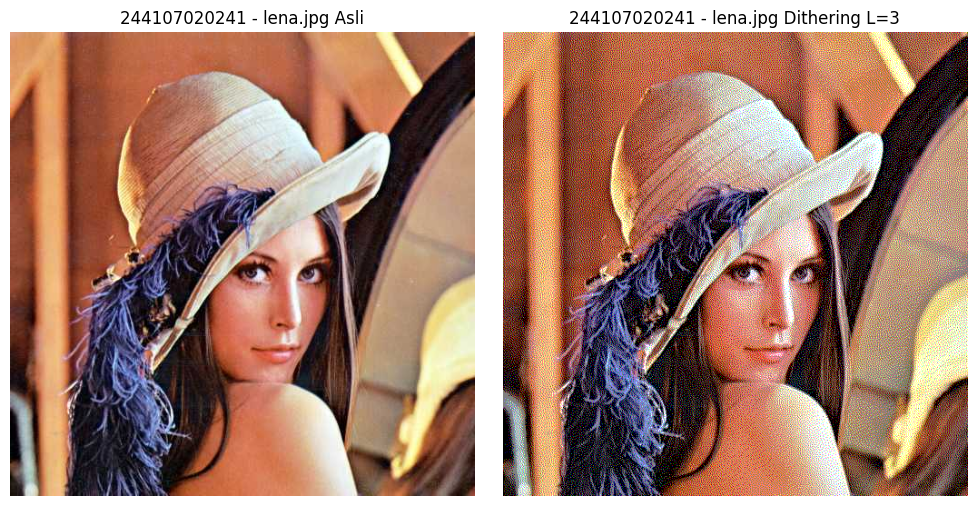

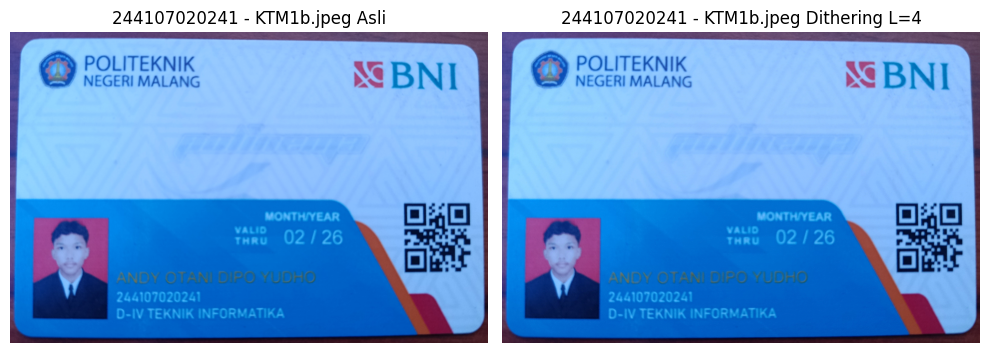

Level Lena : 3
Level KTM  : 4


In [ ]:

# TAHAP 1 - lena.jpg
hasil_lena = dithering_warna(
    BASE + '/lena.jpg',
    'lena.jpg',
    3
)


# TAHAP 2 - KTM1b.jpg
hasil_ktm = dithering_warna(
    BASE + '/244107020241/KTM1b.jpeg',
    'KTM1b.jpeg',
    PARAM['L']
)

print("Level Lena :", 3)
print("Level KTM  :", PARAM['L'])

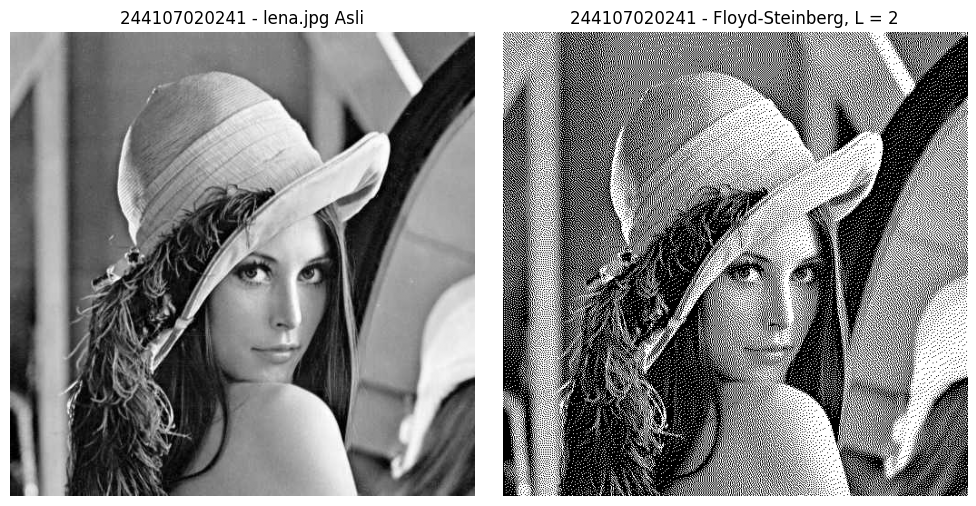

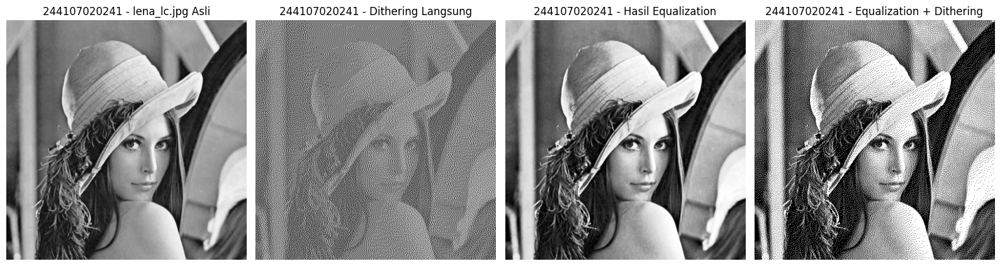

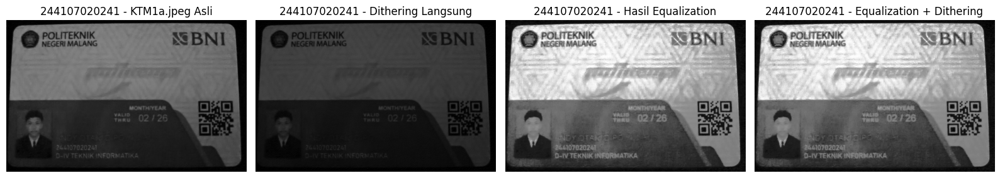

In [ ]:
BASE = '/content/drive/MyDrive/PCVK/Images'


# FUNGSI FLOYD-STEINBERG
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):

            lama = img[y, x]

            # Kuantisasi ke level terdekat
            baru = np.round(lama / step) * step

            img[y, x] = baru

            # Hitung error
            error = lama - baru

            # Sebarkan error
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)



# BAGIAN 1
# LENA.JPG - FLOYD STEINBERG L = 2
lena = cv.imread(
    BASE + '/lena.jpg',
    cv.IMREAD_GRAYSCALE
)

if lena is None:
    print('lena.jpg tidak ditemukan')

else:
    lena_dither = floyd_steinberg(
        lena,
        L=2
    )

    plt.figure(figsize=(10, 5))

    # Lena asli
    plt.subplot(1, 2, 1)
    plt.imshow(
        lena,
        cmap='gray'
    )
    plt.title(
        NIM + ' - lena.jpg Asli'
    )
    plt.axis('off')

    # Lena dithering
    plt.subplot(1, 2, 2)
    plt.imshow(
        lena_dither,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Floyd-Steinberg, L = 2'
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# FUNGSI:
# DITHERING LANGSUNG vs EQUALIZATION + DITHERING
def he_dithering(path, nama):

    # Baca citra grayscale
    gray = cv.imread(
        path,
        cv.IMREAD_GRAYSCALE
    )

    if gray is None:
        print('Gambar tidak ditemukan:', path)
        return



    # 1. DITHERING LANGSUNG
    dither_langsung = floyd_steinberg(
        gray,
        L=2
    )



    # 2. HISTOGRAM EQUALIZATION
    equalized = cv.equalizeHist(gray)



    # 3. EQUALIZATION + DITHERING
    equalized_dither = floyd_steinberg(
        equalized,
        L=2
    )



    # TAMPILKAN SEMUA DALAM 1 LAYOUT
    plt.figure(figsize=(16, 5))


    # Citra asli
    plt.subplot(1, 4, 1)
    plt.imshow(
        gray,
        cmap='gray'
    )
    plt.title(
        NIM + ' - ' + nama + ' Asli'
    )
    plt.axis('off')


    # Dithering langsung
    plt.subplot(1, 4, 2)
    plt.imshow(
        dither_langsung,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Dithering Langsung'
    )
    plt.axis('off')


    # Hasil equalization
    plt.subplot(1, 4, 3)
    plt.imshow(
        equalized,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Hasil Equalization'
    )
    plt.axis('off')


    # Equalization kemudian dithering
    plt.subplot(1, 4, 4)
    plt.imshow(
        equalized_dither,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Equalization + Dithering'
    )
    plt.axis('off')


    plt.tight_layout()
    plt.show()


# BAGIAN 2
# TAHAP 1 - lena_lc.jpg
he_dithering(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# TAHAP 2 - KTM1a.jpg
he_dithering(
    BASE + '/244107020241/KTM1a.jpeg',
    'KTM1a.jpeg'
)

Pada percobaan ini dilakukan perbandingan antara dithering langsung dan dithering setelah histogram equalization.

Hasil menunjukkan bahwa citra yang melalui histogram equalization terlebih dahulu memiliki kontras lebih baik sehingga detail objek lebih mudah dikenali setelah proses dithering.

Urutan terbaik adalah melakukan histogram equalization terlebih dahulu kemudian dithering, karena distribusi intensitas yang lebih baik menghasilkan citra akhir yang lebih jelas.

Berdasarkan seluruh percobaan, histogram dapat digunakan untuk menganalisis distribusi intensitas citra. Histogram equalization mampu meningkatkan kontras dengan memperbaiki penyebaran intensitas piksel, sedangkan CLAHE memberikan peningkatan kontras lokal yang lebih baik. Selain itu, metode dithering Floyd-Steinberg dapat mengurangi jumlah level warna dengan tetap mempertahankan kualitas visual citra melalui penyebaran error ke piksel sekitar.